# Neural networks: from scikit-learn to PyTorch and probabilistic networks

COMP0173 AI for Sustainable Development  
**Lab 3 · 60 minutes · Google Colab (CPU is fine)**

## Overview

We will recognise handwritten digits with a linear perceptron, a neural network in scikit-learn and a deeper network in PyTorch. Then we will make the weights *probabilistic*, so we can explore predictions where the model is unsure. We will also compare **Bayesian networks and deep ensembles** on the same digits and ask why their uncertainty estimates can differ.

We will learn **what an ablation study is** and why it matters in machine learning, and **why every model needs a sensible baseline**. Finally, we will look at student performance: how would we judge a model intended to offer extra educational support, and can we trust its probabilities?

**Plan (60 minutes):** introduction and activations (6 min); digits and data splits (9 min); PyTorch and ablations (12 min); uncertainty and ensemble comparison (21 min); education, baselines and calibration (10 min); conclusions (2 min). Most model training code is provided so that there is time to discuss results.


## Before you start

### Learning outcomes

By the end of this lab, you should be able to:
- describe layers, parameters, activation functions and gradient-based learning;
- compare models without using the test set for development or model selection;
- explain **ablations** and use one to test whether a design choice helps;
- distinguish a **baseline** from a meaningful improvement in model performance;
- explain why Bayesian networks represent uncertainty in their weights, and compare their uncertainty estimates with a deep ensemble;
- explain **probability calibration**, class imbalance and the consequences of predictions in education.

### How to work through this lab

Save your own copy with *File → Save a copy in Drive*. Run cells in order. Questions are marked ✏️. Discuss answers with a neighbour and write short responses. Some questions ask you to complete a little code. Solutions will be released after the lab.

Both datasets download automatically. No manual upload or GPU is needed. We use small training subsets so there is time to discuss the results. Run the training code as provided; most of your work is interpreting the experiments.

---

## 1. How do neural networks learn? (7 min)

The idea of an artificial neuron goes back to McCulloch and Pitts in 1943. Rosenblatt's perceptron in the 1950s could learn a linear decision rule. But many tasks require more than a linear boundary. Networks with hidden layers became easier to train when backpropagation was widely adopted in the 1980s.

Deep learning became much more practical in the 2010s, thanks to larger datasets, faster hardware and advances in optimisation. Today, a neural network might have a handful of layers or many more. The same basic ideas still apply: compute a prediction, measure its error and adjust the parameters.

A neuron first computes a **weighted sum** of its inputs plus a **bias**: $z = w_1x_1 + \cdots + w_dx_d + b$. It then applies an **activation function**, $a = f(z)$. A layer contains several neurons, each learning different weights. Their outputs become the inputs to the next layer. During training, a **loss function** measures the difference between predictions and targets. **Backpropagation** calculates gradients of the loss, and an optimiser (such as stochastic gradient descent or Adam) uses these gradients to update the weights and biases.

Hidden layers let the network learn useful intermediate features rather than relying only on the raw inputs. In handwritten digits, one layer might respond to simple strokes, while later layers can combine information into more complicated patterns. More layers give a model additional ways to represent relationships, but also make training and model selection more difficult.

### Why use a non-linear activation?

A layer of neurons combines its inputs using weights and adds a bias. This is called an **affine transformation**: for a single input, it has the form $y = wx + b$. If we stack layers that only do this, the result is still just a weighted sum plus a bias. For example, applying $y = 2x + 1$ and then $z = 3y - 4$ is equivalent to $z = 6x - 1$. One layer could do the same job. **Activation functions introduce non-linearity**, allowing the network to learn more complex relationships that cannot be represented by a single weighted sum.

Two familiar activations are **sigmoid**, $\sigma(z)=1/(1+e^{-z})$, and **ReLU**, $\mathrm{ReLU}(z)=\max(0,z)$. Sigmoid maps inputs smoothly to values between 0 and 1. But for large positive or negative inputs the curve becomes almost flat. Its derivative is then close to zero, which can make gradients very small as they pass back through many layers. This is one reason for the **vanishing-gradient problem**.

ReLU is widely used in hidden layers because it is simple and has a gradient of 1 when its input is positive. This often makes deep networks easier to train. It has a weakness too: its gradient is zero for negative inputs. If a neuron keeps receiving negative values, it may stop updating its weights. This is sometimes called a **dying ReLU**. ReLU is not always the right choice. Sigmoid is still useful, for example when an output needs to represent a probability in binary classification.

A related result is the **universal approximation theorem**. Under suitable conditions, a network with a non-linear activation and enough neurons can approximate any continuous function on a bounded domain as closely as we like. This is a statement about what a network *can represent*, not a promise that training will find the function or that it will generalise to new data. Compare the two activations below.

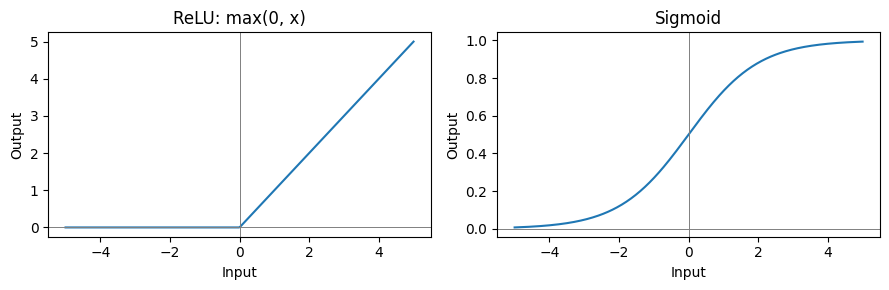

In [1]:
# Run this cell
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score

SEED = 7
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)  # More predictable performance on the free Colab CPU
DEVICE = torch.device('cpu')

x = np.linspace(-5, 5, 300)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(x, np.maximum(x, 0)); axes[0].set_title('ReLU: max(0, x)')
axes[1].plot(x, 1 / (1 + np.exp(-x))); axes[1].set_title('Sigmoid')
for ax in axes:
    ax.axhline(0, color='gray', lw=.7)
    ax.axvline(0, color='gray', lw=.7)
    ax.set_xlabel('Input'); ax.set_ylabel('Output')
plt.tight_layout(); plt.show()

> ✏️ **Question 1.1.** If we removed every ReLU from a deep network, would adding more linear layers make the model more expressive? Why?

✍️ *Your answer: type here, replacing this text.*

> ✏️ **Question 1.2.** Why is ReLU often used instead of sigmoid in hidden layers? What is one drawback of ReLU?

✍️ *Your answer: ReLu is a more robust activation function as compared to the sigmoid. ReLU can 

---

## 2. Handwritten digits with scikit-learn (10 min)

We will use the classical **MNIST** dataset. Each image shows a handwritten digit from 0 to 9. It has 28 × 28 pixels, so for these fully connected networks we flatten each image into **784 numbers**. Convolutional networks make better use of image structure, but fully connected networks are easier to study first.

We will start with a **perceptron**, which learns a linear classifier. Then we will try scikit-learn's `MLPClassifier`, which has a hidden layer with ReLU. In the next section, we will build a deeper network in PyTorch.

### Training, validation and test sets

- **Training data** are used to learn weights and biases.
- **Validation data** are used to choose the model, learning rate, number of epochs and other hyperparameters. We can also run cross-validation **within the development data**.
- **Test data** are set aside for a final estimate of how the chosen model performs on unseen cases.

**The test set must stay completely unseen during development.** Do not use it for training, cross-validation, choosing architectures, tuning thresholds or deciding when to stop. Even if no test images enter the training loop, choosing a model using test accuracy still uses information from those images. The resulting estimate can be too optimistic.

We will compare the models on the validation data. Only after that will we evaluate them on the official MNIST test set.

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 479kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.46MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.16MB/s]


Train: 4800  Validation: 1200  Official test: 10000 (still untouched)


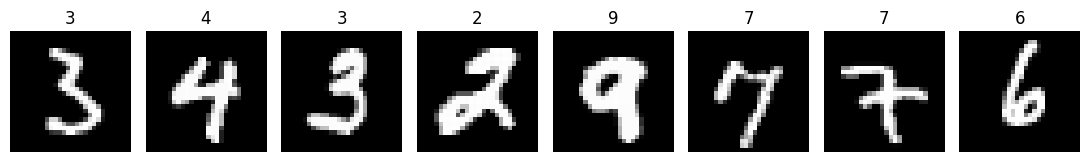

In [2]:
# Run this cell: download MNIST and prepare the *same split* for all models
# torchvision is already available in standard Colab runtimes; do not pin an old PyTorch version.
from torchvision.datasets import MNIST

mnist_train = MNIST(root='./mnist_data', train=True, download=True)
mnist_test = MNIST(root='./mnist_data', train=False, download=True)

# Use a smaller, fixed sample of the 60,000 training images for this one-hour lab.
rng = np.random.default_rng(SEED)
chosen = rng.choice(len(mnist_train), size=6000, replace=False)
X_dev = mnist_train.data[chosen].numpy().reshape(-1, 784).astype('float32') / 255.0
y_dev = mnist_train.targets[chosen].numpy()
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.2, stratify=y_dev, random_state=SEED)
print(f'Train: {len(y_train)}  Validation: {len(y_val)}  Official test: {len(mnist_test)} (still untouched)')

fig, axes = plt.subplots(1, 8, figsize=(11, 2))
for ax, im, label in zip(axes, X_train[:8], y_train[:8]):
    ax.imshow(im.reshape(28, 28), cmap='gray'); ax.set_title(str(label)); ax.axis('off')
plt.tight_layout(); plt.show()

In [3]:
# Run this cell: linear perceptron and a small neural network
per = Perceptron(max_iter=35, random_state=SEED, tol=1e-3)
per.fit(X_train, y_train)

mlp = MLPClassifier(hidden_layer_sizes=(64,), activation='relu',
                    solver='adam', max_iter=35, random_state=SEED,
                    early_stopping=False)
mlp.fit(X_train, y_train)

val_scores = {
    'Linear perceptron': accuracy_score(y_val, per.predict(X_val)),
    'scikit-learn MLP (64)': accuracy_score(y_val, mlp.predict(X_val)),
}
print(pd.Series(val_scores, name='Validation accuracy').round(3))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


Linear perceptron        0.860
scikit-learn MLP (64)    0.913
Name: Validation accuracy, dtype: float64


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (35) reached and the optimization hasn't converged yet.
  warnings.warn(


> ✏️ **Question 2.1.** Does the MLP do better than the linear perceptron on the validation set? Why might this happen? Is better validation accuracy enough to say that a model will work on any handwriting?

✍️ 
- Yes, the MLP does perform better than the linear perceptron.
- this is because the MLP's hidden layers make use of the relu activation function which is more capable of learning the non linear decision boundaries. 
- no, a better validation accuracy does not mean that a model is capable of predicting handwriting outside of its trained dataset. 

> ✏️ **Question 2.2.** You try five architectures, choose the one with the highest **test accuracy**, and then deploy it. Its performance is worse than you expected. What might explain the difference? How should you have selected the architecture instead?

- test accuracy alone is not the best indicator of model performance. 
- worse performance can be due to the model 
- architecture shoould be selected out of the best training and validation data. test set is for final benchmarking. 

<details><summary><strong>Key points</strong> (open once you have answered the questions)</summary>

The perceptron learns a linear decision rule. A multilayer perceptron can learn non-linear rules because of its hidden layer and activation. Compare scores on *validation*, not test, while deciding which network to use.

</details>

---

## 3. A deeper network in PyTorch (14 min)

Scikit-learn makes it easy to fit a network in a few lines. PyTorch gives us direct control over the layers and training loop. Here we will define a **four-layer fully connected network** (`FCN`), train it in small batches, and compare it with the simpler models.

A **batch** is a small group of examples; an **epoch** is one pass through all training examples. The **cross-entropy loss** penalises incorrect class probabilities. Backpropagation calculates how each parameter affects that loss, and the optimiser updates those parameters after each batch.

In [4]:
# Run this cell: define and train a four-layer fully connected network
CLASSES = 10
BATCH_SIZE = 128
INPUT_HEIGHT, INPUT_WIDTH = 28, 28

train_loader = DataLoader(TensorDataset(torch.from_numpy(X_train),
                                         torch.from_numpy(y_train).long()),
                          batch_size=BATCH_SIZE, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(TensorDataset(torch.from_numpy(X_val),
                                       torch.from_numpy(y_val).long()),
                        batch_size=256, shuffle=False)

class FCN(nn.Module):
    """Four linear layers, with ReLU between them."""
    def __init__(self, n_hidden=64, n_classes=CLASSES, use_relu=True):
        super().__init__()
        self.l1 = nn.Linear(INPUT_HEIGHT * INPUT_WIDTH, n_hidden)
        self.l2 = nn.Linear(n_hidden, n_hidden)
        self.l3 = nn.Linear(n_hidden, n_hidden)
        self.l4 = nn.Linear(n_hidden, n_classes)
        self.activation = nn.ReLU() if use_relu else nn.Identity()

    def forward(self, x):
        x = x.reshape(-1, INPUT_HEIGHT * INPUT_WIDTH)
        x = self.activation(self.l1(x))
        x = self.activation(self.l2(x))
        x = self.activation(self.l3(x))
        return self.l4(x)  # raw scores: CrossEntropyLoss applies softmax internally

def train_fcn(net, optimizer, loader):
    net.train()
    for images, labels in loader:
        optimizer.zero_grad()
        loss = F.cross_entropy(net(images), labels)
        loss.backward()
        optimizer.step()

def accuracy_torch(net, loader):
    net.eval(); correct = total = 0
    with torch.no_grad():
        for images, labels in loader:
            predictions = net(images).argmax(dim=1)
            correct += int((predictions == labels).sum())
            total += len(labels)
    return correct / total

fcn = FCN(n_hidden=64, use_relu=True).to(DEVICE)
# Save its initial weights, so the ablation can start from the same values.
fcn_initial_state = {k: v.detach().clone() for k, v in fcn.state_dict().items()}
train_loader.generator.manual_seed(SEED)
optimizer = torch.optim.Adam(fcn.parameters(), lr=0.002)
for epoch in range(3):
    train_fcn(fcn, optimizer, train_loader)
    print(f'Epoch {epoch+1}: validation accuracy = {accuracy_torch(fcn, val_loader):.3f}')
val_scores['PyTorch FCN (4 layers)'] = accuracy_torch(fcn, val_loader)

Epoch 1: validation accuracy = 0.783
Epoch 2: validation accuracy = 0.863
Epoch 3: validation accuracy = 0.882


In [5]:
# Run this cell: compare on validation data, not test data
pd.Series(val_scores, name='Validation accuracy').sort_values(ascending=False).round(3)

,Validation accuracy
scikit-learn MLP (64),0.913
PyTorch FCN (4 layers),0.882
Linear perceptron,0.860


> ✏️ **Question 3.1.** Did the deeper PyTorch network beat the scikit-learn MLP? Why might a deeper model fail to improve accuracy? What would you compare to make a fairer claim about depth?

- no, the deeper PyTorch network does not beat the scikit-learn MLP.
- the deeper model might have more parameters, might be undertrained, may be unoptimised.
- a fair comparison would use a level-playing field. Equal Optimization settings, parameter counts, equal convergence and multiple random seeds. 

> ✏️ **Question 3.2.** Count the trainable parameters in the PyTorch network. Why might a model with more parameters not always perform better?

In [ ]:
# Question 3.2: complete the parameter count
parameter_count = ...   # use fcn.parameters() and p.numel()
print('FCN trainable parameters:', parameter_count)

✍️ *Your answer: type here, replacing this text.*

<details><summary><strong>Key points</strong> (open once you have answered the questions)</summary>

More layers mean more capacity, not guaranteed improvement. An ablation tests one component by changing or removing it and retraining with the other settings fixed. The result may still vary by random seed. The current results are a first comparison. They do not show that one software library is inherently better than the other.

</details>

### Ablation studies: does a component really help?

In machine learning, an **ablation study** checks the contribution of a model component by removing or changing it and comparing the result. For example, does a network perform worse if we remove ReLU? Or if we remove one hidden layer?

Ablations matter because good performance alone does not tell us **which parts of a model are useful**. A complicated model may include components that add little, or may improve simply because of the way it was trained. When possible, an ablation changes **one thing at a time**: use the same training and validation data, keep other settings fixed, and retrain the model. Random initialization and data order can also affect results, so more careful studies repeat experiments with several random seeds. Never use the held-out test set to choose which components to keep.

> ✏️ **Question 3.3.** **Ablation.** Train the same four-layer network *without ReLU*, starting from the same initial weights. Compare its validation accuracy with the original network. What does this tell you about the role of activation functions?

In [8]:
# Question 3.3: remove the ReLU activations and retrain from the same starting weights.
# Complete the TWO lines marked ... .
fcn_no_relu = FCN(use_relu=False ) # FCN with use_relu=False
fcn_no_relu.load_state_dict(fcn_initial_state)
ablation_optimizer = torch.optim.Adam(fcn_no_relu.parameters(), lr=0.002)
train_loader.generator.manual_seed(SEED)  # same minibatch order as the original FCN
for epoch in range(3):
    train_fcn(fcn_no_relu, ablation_optimizer, train_loader)
no_relu_accuracy = accuracy_torch(fcn_no_relu, val_loader)  # accuracy_torch on val_loader
print('With ReLU:   ', round(val_scores['PyTorch FCN (4 layers)'], 3))
print('Without ReLU:', round(no_relu_accuracy, 3))

With ReLU:    0.882
Without ReLU: 0.875


- activation functions are very important and can significantly affect model performance
- without relu, the model performs worse 

---

## 4. Probabilistic neural networks: where are we unsure? (17 min)

### First, a simple probability distribution

Suppose we are uncertain about a measurement. We could describe it by a single best guess, such as 10, or by a probability distribution centred at 10. The distribution tells us how much the value might vary. A narrow Normal distribution has less spread than a wide one. Below, the two distributions have the same mean but different standard deviations.

In [ ]:
# Run this cell: a simple distribution example
from scipy.stats import norm
xx = np.linspace(4, 16, 300)
plt.figure(figsize=(7, 3))
for sd in (0.5, 2.0):
    plt.plot(xx, norm.pdf(xx, loc=10, scale=sd), label=f'Mean = 10, SD = {sd}')
plt.xlabel('Possible value'); plt.ylabel('Probability density')
plt.title('Same estimate, different uncertainty'); plt.legend(); plt.show()

> ✏️ **Question 4.1.** Both distributions have the same mean. What information would we lose if we reported only that mean?

✍️ *Your answer: type here, replacing this text.*

### Two sources of predictive uncertainty

We often distinguish between:

- **Aleatoric uncertainty:** uncertainty due to variation or ambiguity in the data, such as an unclear handwritten digit. It may remain even if we collect more examples.
- **Epistemic uncertainty:** uncertainty about the model or its parameters, for example because some kinds of handwriting were scarce in the training set. More informative training data can sometimes reduce it.

The distinction is useful, but a single uncertainty score does not necessarily separate the two. In particular, **predictive entropy**, which we use below, measures how spread out the final predicted class probabilities are; it can reflect both sources.

### A distribution for each weight

A standard neural network learns one value for each weight. But with limited training data, different weight values may explain the observations reasonably well. A **Bayesian neural network (BNN)** represents uncertainty about these parameters by learning an approximation to a distribution over weights. It can sample several sets of weights and average the predictions.

In our implementation, each weight has a Gaussian distribution described by two trainable values:

- **`mu` ($\mu$):** the mean of the weight distribution.
- **`rho` ($\rho$):** an unconstrained parameter used to calculate the positive standard deviation, $\sigma = \log(1+e^{\rho})$ (the *softplus* function). We learn `rho` instead of learning $\sigma$ directly because a standard deviation cannot be negative.

Blundell and colleagues introduced **Bayes by Backprop** in their 2015 paper [*Weight Uncertainty in Neural Networks*](https://arxiv.org/abs/1505.05424). Their method uses gradients to learn an approximate distribution over weights. It builds on earlier Bayesian work. We will use a simple version with Gaussian weight distributions, a mixture-of-Gaussians prior, and a training objective based on the **evidence lower bound (ELBO)**. You do not need to derive the ELBO here.

The model makes predictions using different samples of its weights. The variation helps us inspect how stable its predictions are. The resulting probabilities are **not automatically calibrated**, and uncertainty cannot be completely described by variation between samples.

A different approach is a **deep ensemble**: train several ordinary networks independently, using different initialisations, and compare their predictions. This does not explicitly learn a probability distribution over weights.

### The probabilistic network

Read the main steps in the code below. `Gaussian` defines how to sample weights, and `BayesianLinear` replaces each ordinary linear layer. Its parameters `w_mu` and `w_rho` describe weight distributions; the bias has corresponding parameters. The prior is a mixture of two Gaussians, so both components must be included when evaluating its probability. We will still use a four-layer network.

In [ ]:
# Run this cell: define Gaussian weight distributions and Bayesian linear layers
import math

class Gaussian:
    def __init__(self, mu, rho):
        self.mu, self.rho = mu, rho

    @property
    def sigma(self):
        return F.softplus(self.rho)  # positive standard deviation

    def sample(self):
        return self.mu + self.sigma * torch.randn_like(self.mu)

    def log_prob(self, value):
        return torch.distributions.Normal(self.mu, self.sigma).log_prob(value).sum()

class ScaledGaussianMixture:
    def __init__(self, pi=0.5, sigma1=1.0, sigma2=math.exp(-6)):
        self.pi, self.sigma1, self.sigma2 = pi, sigma1, sigma2

    def log_prob(self, value):
        a = torch.distributions.Normal(0., self.sigma1).log_prob(value) + math.log(self.pi)
        b = torch.distributions.Normal(0., self.sigma2).log_prob(value) + math.log(1 - self.pi)
        return torch.logaddexp(a, b).sum()  # both Gaussian components matter

class BayesianLinear(nn.Module):
    def __init__(self, dim_in, dim_out):
        super().__init__()
        self.w_mu = nn.Parameter(torch.empty(dim_out, dim_in).normal_(0, 0.05))
        self.w_rho = nn.Parameter(torch.full((dim_out, dim_in), -4.5))
        self.b_mu = nn.Parameter(torch.zeros(dim_out))
        self.b_rho = nn.Parameter(torch.full((dim_out,), -4.5))
        self.w = Gaussian(self.w_mu, self.w_rho)
        self.b = Gaussian(self.b_mu, self.b_rho)
        self.prior = ScaledGaussianMixture()
        self.log_prior = torch.tensor(0.)
        self.log_variational_post = torch.tensor(0.)

    def forward(self, x, sample=False):
        w = self.w.sample() if (self.training or sample) else self.w.mu
        b = self.b.sample() if (self.training or sample) else self.b.mu
        if self.training:
            self.log_prior = self.prior.log_prob(w) + self.prior.log_prob(b)
            self.log_variational_post = self.w.log_prob(w) + self.b.log_prob(b)
        return F.linear(x, w, b)

In [ ]:
# Run this cell: train the four-layer BNN on the same training images as the FCN
class BNN(nn.Module):
    def __init__(self, n_hidden=64):
        super().__init__()
        self.l1 = BayesianLinear(784, n_hidden)
        self.l2 = BayesianLinear(n_hidden, n_hidden)
        self.l3 = BayesianLinear(n_hidden, n_hidden)
        self.l4 = BayesianLinear(n_hidden, CLASSES)

    def forward(self, x, sample=False):
        x = x.reshape(-1, 784)
        x = F.relu(self.l1(x, sample=sample))
        x = F.relu(self.l2(x, sample=sample))
        x = F.relu(self.l3(x, sample=sample))
        return self.l4(x, sample=sample)

    def elbo(self, images, labels, n_training, n_samples=2):
        # Approximate expected classification loss and KL penalty using weight samples.
        estimate = 0.
        for _ in range(n_samples):
            logits = self(images, sample=True)
            classification_loss = F.cross_entropy(logits, labels)
            layers = (self.l1, self.l2, self.l3, self.l4)
            kl = sum(layer.log_variational_post - layer.log_prior for layer in layers)
            estimate = estimate + classification_loss + kl / n_training
        return estimate / n_samples

# Train on the same development-training split as the ordinary FCN.
# Approximate weight distributions usually need a longer training budget.
# The test images remain untouched.
torch.manual_seed(SEED)
bnn = BNN(n_hidden=64).to(DEVICE)
bnn_opt = torch.optim.Adam(bnn.parameters(), lr=0.002)
BNN_EPOCHS = 8
for epoch in range(BNN_EPOCHS):
    bnn.train()
    epoch_loss = 0.
    for images, labels in train_loader:
        bnn_opt.zero_grad()
        loss = bnn.elbo(images, labels, n_training=len(X_train), n_samples=2)
        loss.backward()
        bnn_opt.step()
        epoch_loss += loss.item()
    if (epoch + 1) % 2 == 0:
        # Mean weights provide a quick indication of whether training is progressing.
        bnn.eval()
        with torch.no_grad():
            mean_accuracy = np.mean([
                (bnn(images, sample=False).argmax(1) == labels).float().mean().item()
                for images, labels in val_loader
            ])
        print(f'BNN epoch {epoch+1}: loss = {epoch_loss / len(train_loader):.2f}, '
              f'validation accuracy (mean weights) ≈ {mean_accuracy:.3f}')

### Which digits make the model unsure?

For each validation image, we sample the BNN's weights **30 times**, calculate the predicted class probabilities and average them. We then calculate **predictive entropy**:

$$H(x) = -\sum_{k=0}^{9} \bar p_k(x)\,\log \bar p_k(x).$$

Here $\bar p_k(x)$ is the **average predicted probability** for digit $k$ across weight samples. High entropy means that the model spreads probability over several digits instead of strongly favouring one. This is an uncertainty score for the *final prediction*, not a pure measure of epistemic uncertainty.

We will rank **all validation images** by entropy and examine the ten highest.

In [ ]:
# Run this cell: predictions from sampled BNN weights on all validation images
bnn.eval()
prob_samples = []
with torch.no_grad():
    inputs = torch.from_numpy(X_val)
    for sample_id in range(30):
        batch_probs = []
        for batch in torch.split(inputs, 256):
            batch_probs.append(F.softmax(bnn(batch, sample=True), dim=1).numpy())
        prob_samples.append(np.concatenate(batch_probs))
mean_probs = np.mean(prob_samples, axis=0)  # shape: (n_validation, 10)
uncertainty = -(mean_probs * np.log(np.clip(mean_probs, 1e-12, 1))).sum(axis=1)
print('Predictive entropy (min / median / max):', np.round(np.percentile(uncertainty, [0, 50, 100]), 3))

> ✏️ **Question 4.2.** Find and display the **10 validation digits with the highest predictive entropy**. Include the true label, predicted label and entropy for each. Can you see why the model may find them difficult?

In [ ]:
# Question 4.2: complete one line and run the plotting code.
# Hint: np.argsort(...) returns indices from smallest to largest.
top10 = ...        # replace with indices of the TEN HIGHEST values of uncertainty
predicted = mean_probs.argmax(axis=1)  # predicted digit from mean probabilities

if top10 is Ellipsis:
    raise ValueError("Complete top10 with the indices of the ten highest entropies.")

fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for ax, idx in zip(axes.flat, top10):
    ax.imshow(X_val[idx].reshape(28, 28), cmap='gray')
    ax.set_title(f'True {y_val[idx]} / pred {predicted[idx]}\nH={uncertainty[idx]:.2f}')
    ax.axis('off')
plt.tight_layout()
plt.show()

✍️ *Your answer: type here, replacing this text.*

### Comparing uncertainty: Bayesian network versus deep ensemble

We have used **Bayes by Backprop** to sample plausible network weights. Another common method is a **deep ensemble**: train several ordinary networks independently, using different random initialisations, and average their predicted class probabilities.

Both approaches can be used to estimate uncertainty, but they are not the same:

- The **BNN** samples weights from a learned *approximate posterior*. Its estimates depend on the prior, the approximation and the training procedure.
- The **ensemble** averages predictions from independently trained networks. Its estimates depend on the training setup, the number of members and how different those members are.

We will use **predictive entropy for both methods**, calculated from their **averaged class probabilities**. This puts the scores on the same scale, from 0 to $\log(10)\approx2.30$ for ten classes. A high score means the final prediction is spread over several digits. But this does **not** necessarily mean the ensemble members disagree. Imagine that all three networks assign 50% probability to a 3 and 50% to an 8. They all agree, yet their averaged prediction has high entropy. We could also get high entropy if one network is very confident about a 3 and another is very confident about an 8. In that case they **disagree**. Predictive entropy alone cannot tell these two situations apart. To study disagreement specifically, we would need to examine the individual predictions.

Our comparison is a classroom demonstration: the BNN uses 30 weight samples and a longer training schedule, whereas the ensemble has only three networks. Their uncertainty estimates can differ because of **both the method and these practical choices**. We cannot infer that one method is generally better from this experiment.


> ✏️ **Question 4.3.** Build an ensemble. Train two more copies of our PyTorch network (the first copy is already trained). Complete the two lines that (i) average the **probabilities** across the three models and (ii) calculate predictive entropy from those averaged probabilities. Why should we average probabilities, rather than predicted digit labels?

In [ ]:
# Question 4.3: train a small three-member deep ensemble (including our earlier FCN).
# We provide the training loop to leave time for analysing uncertainty.
ensemble_models = [fcn]
for member_seed in [17, 27]:
    torch.manual_seed(member_seed)
    member = FCN(n_hidden=64, use_relu=True).to(DEVICE)
    opt = torch.optim.Adam(member.parameters(), lr=0.002)
    for epoch in range(3):  # same training budget as the original FCN
        train_fcn(member, opt, train_loader)
    ensemble_models.append(member)

with torch.no_grad():
    val_tensor = torch.from_numpy(X_val)
    member_probs = np.stack([
        F.softmax(net.eval()(val_tensor), dim=1).numpy()
        for net in ensemble_models
    ])  # shape: (3 networks, n_validation, 10 digits)

ensemble_probs = ...     # average class probabilities over the 3 networks
ensemble_entropy = ...   # entropy of ensemble_probs; use the BNN formula above

if ensemble_probs is Ellipsis or ensemble_entropy is Ellipsis:
    raise ValueError('Complete both lines to calculate ensemble uncertainty.')
print('Ensemble validation accuracy:',
      round(accuracy_score(y_val, ensemble_probs.argmax(axis=1)), 3))
print('Mean ensemble entropy:', round(float(ensemble_entropy.mean()), 3))


✍️ *Your answer: type here, replacing this text.*

> ✏️ **Question 4.4.** Where do the methods disagree? Complete the two lines below to find the **four validation digits** with the biggest *absolute difference* in predictive entropy between the ensemble and BNN. Look at their images and predictions. Are the methods uncertain about the same examples?

In [ ]:
# Question 4.4: compare entropy for exactly the SAME validation images.
# We use absolute difference: either model may have the higher entropy.
entropy_gap = ...         # absolute difference between ensemble_entropy and uncertainty
most_different = ...     # indices of the FOUR largest gaps, highest first

if entropy_gap is Ellipsis or most_different is Ellipsis:
    raise ValueError('Complete both lines to find the largest disagreements.')

# Each point in the scatter plot is one validation digit.
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(ensemble_entropy, uncertainty, s=12, alpha=0.4)
ax.plot([0, np.log(10)], [0, np.log(10)], 'k--', lw=1)
ax.set(xlabel='Ensemble predictive entropy', ylabel='BNN predictive entropy',
       xlim=(0, np.log(10)), ylim=(0, np.log(10)),
       title='Same digit, two uncertainty estimates')
plt.tight_layout(); plt.show()

# How many images appear in BOTH models' top-ten most uncertain lists?
bnn_top10 = set(np.argsort(uncertainty)[-10:])
ens_top10 = set(np.argsort(ensemble_entropy)[-10:])
print('Overlap in the two top-ten lists:', len(bnn_top10 & ens_top10), 'out of 10')

fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, idx in zip(axes, most_different):
    ax.imshow(X_val[idx].reshape(28, 28), cmap='gray')
    ax.set_title(f'True {y_val[idx]} | BNN {mean_probs[idx].argmax()} | Ens {ensemble_probs[idx].argmax()}\n'
                 f'BNN H={uncertainty[idx]:.2f}, Ens H={ensemble_entropy[idx]:.2f}', fontsize=9)
    ax.axis('off')
plt.tight_layout(); plt.show()


✍️ *Your answer: type here, replacing this text.*

### Accuracy is not enough: the Brier score

Two networks can get the same number of digits right but assign very different probabilities. If the correct digit is 7, predicting a 90% probability for 7 is more informative than predicting 20% (even if 7 is still the most likely class).

The **Brier score** measures how close predicted class probabilities are to the actual outcomes. For ten-class MNIST, we represent the true digit with a 1 for its class and 0 for the others, and add up the squared errors over all classes. We average this across images. **Lower is better; 0 is perfect.** This multiclass score measures probability quality, not calibration alone. We can use it alongside accuracy to compare the two methods.

In [ ]:
# Run this cell: two simple validation checks of predictive quality.
# The Brier score rewards probability estimates close to the actual one-hot labels.
# Lower is better. We use validation data for this classroom comparison, not the test set.
def multiclass_brier(probs, labels):
    truth = np.eye(probs.shape[1])[labels]
    return np.mean(np.sum((probs - truth) ** 2, axis=1))

comparison_table = pd.DataFrame({
    'Accuracy': [accuracy_score(y_val, mean_probs.argmax(axis=1)),
                 accuracy_score(y_val, ensemble_probs.argmax(axis=1))],
    'Multiclass Brier (lower = better)': [multiclass_brier(mean_probs, y_val),
                                         multiclass_brier(ensemble_probs, y_val)],
    'Mean predictive entropy': [uncertainty.mean(), ensemble_entropy.mean()],
}, index=['Bayesian network', 'Deep ensemble (3 models)'])
display(comparison_table.round(3))


if (comparison_table.loc['Deep ensemble (3 models)', 'Accuracy'] > comparison_table.loc['Bayesian network', 'Accuracy']
        and comparison_table.loc['Deep ensemble (3 models)', 'Multiclass Brier (lower = better)'] < comparison_table.loc['Bayesian network', 'Multiclass Brier (lower = better)']):
    print('Here, the deep ensemble is better on BOTH validation accuracy and Brier score.')
elif (comparison_table.loc['Bayesian network', 'Accuracy'] > comparison_table.loc['Deep ensemble (3 models)', 'Accuracy']
      and comparison_table.loc['Bayesian network', 'Multiclass Brier (lower = better)'] < comparison_table.loc['Deep ensemble (3 models)', 'Multiclass Brier (lower = better)']):
    print('Here, the Bayesian network is better on BOTH validation accuracy and Brier score.')
else:
    print('Here, neither method wins clearly on both validation measures.')

> ✏️ **Question 4.5.** Look at the validation results for the Bayesian neural network and the deep ensemble. Which performs better here when you consider **accuracy, Brier score and mean predictive entropy** together? Why might the methods give different uncertainty estimates for the same digit? What would you check before using either in a real application?

✍️ *Your answer: type here, replacing this text.*

### What can we conclude?

In this experiment, the **deep ensemble performed better** on validation accuracy and Brier score, and produced more confident predictions on average. This is an encouraging result, but it does not mean ensembles always outperform Bayesian neural networks. Next, we evaluate the models on the held-out test set.

### Final evaluation on the held-out MNIST test set

We have finished our model comparisons using validation data. **Only now** do we evaluate the trained models on the official test set to obtain a final estimate of their performance.

In [ ]:
# Run this cell: test set is used for the first time here
X_test = mnist_test.data.numpy().reshape(-1, 784).astype('float32') / 255.0
y_test = mnist_test.targets.numpy()
test_loader = DataLoader(TensorDataset(torch.from_numpy(X_test),
                                        torch.from_numpy(y_test).long()),
                         batch_size=256, shuffle=False)

# A BNN prediction averages probabilities across weight samples.
@torch.no_grad()
def bnn_accuracy(net, loader, n_samples=15):
    net.eval(); correct = total = 0
    for images, labels in loader:
        probs = torch.stack([F.softmax(net(images, sample=True), dim=1)
                             for _ in range(n_samples)]).mean(0)
        correct += (probs.argmax(dim=1) == labels).sum().item()
        total += len(labels)
    return correct / total

test_scores = {
    'Linear perceptron': accuracy_score(y_test, per.predict(X_test)),
    'scikit-learn MLP (64)': accuracy_score(y_test, mlp.predict(X_test)),
    'PyTorch FCN (4 layers)': accuracy_torch(fcn, test_loader),
    'Bayesian neural network': bnn_accuracy(bnn, test_loader),
}
print(pd.Series(test_scores, name='Held-out test accuracy').round(3))

### Why might the scikit-learn network do best?

We set `early_stopping=False`, so it does not hold out data to pick the best epoch. It may stop when training loss stops improving, but it is **not** selecting its architecture using validation scores.

One major difference is **training time**: our scikit-learn MLP runs for up to **35 epochs**, compared with **3 epochs** for the deterministic PyTorch network. The models also have different architectures and optimisation details. These experiments therefore do not tell us that one library or one architecture is generally superior.

**Our MNIST models are deliberately undertrained.** We use only a small subset of the available **60,000 training images**, and limit the number of epochs so everything can run during class. This helps explain why some apparently clear handwritten digits are still misclassified. With more data, suitable architectures (often convolutional networks), and longer training, **accuracy around 99% or higher is achievable on MNIST**. See, for example, [LeCun's discussion of convolutional digit recognition](https://cs.nyu.edu/~yann/talks/lecun-20060816-ciar-2-recog.pdf). These classroom scores are for understanding methods, not a state-of-the-art benchmark.

<details><summary><strong>Key points</strong> (open once you have answered the questions)</summary>

A BNN learns distributions over weights and predicts by sampling them. Predictive entropy describes how spread the mean class probabilities are. It is useful for ranking examples, but it is not proof that the uncertainty estimates are calibrated. We kept the test set separate until the final check.

</details>

---

## 5. Education: predicting student performance (10 min)

Our second example concerns **education (SDG 4)**. The [UCI Student Performance dataset](https://archive.ics.uci.edu/dataset/320/student%2Bperformance) contains school, social and demographic information, and grades, for students at two secondary schools in Portugal. We use the **Portuguese-language course**, with 649 records, and ask whether a student will finish with a grade **below 10 out of 20**.

Imagine a school wants to identify students who may benefit from early support. We remove `G1` and `G2` (grades from later in the year) because they would not be available for an early-warning decision. This also illustrates **data leakage**: using information from the future can make a model look better than it would be in practice.

### Why do we need baselines?

A neural network can sound impressive without being better than a simple rule. A **baseline** gives us a reference: what could we achieve without a complex model? For tomorrow's weather, a useful baseline is **persistence**: predict that tomorrow will be the same as today. If a forecasting model cannot beat that rule, we need to ask what the extra complexity is buying us.

Here we can start with a **dummy classifier** that always predicts the most common outcome, `pass`. That is deliberately simple. It may score quite well on accuracy, but can fail completely at finding students who need support. A useful model should demonstrate an improvement over relevant baselines on the **metrics that matter for the application**. It may involve trade-offs between different metrics, so accuracy alone is not enough.

### What is class imbalance?

If one class is much more common than another, a model may have good **accuracy** while missing many of the rarer cases. Imagine 90 of 100 students pass. Predicting 'pass' for everyone gives 90% accuracy but identifies none of the ten students who may need extra support.

- **Precision (at risk):** of the students flagged, how many really are at risk?
- **Recall (at risk):** of all the students at risk, how many are flagged?
- **F1-score:** a balance between precision and recall.
- **Balanced accuracy:** average recall across the two classes.

Common responses to imbalance include **class weighting** (give the smaller class more influence in training) and **resampling** the training observations. Resampling needs to happen *inside the training split* to avoid leakage. For this exercise, we will start by choosing the right evaluation metrics.

In [ ]:
# Run this cell: load the official UCI archive in Colab, with no manual download
import io, zipfile, urllib.request
UCI_URL = 'https://archive.ics.uci.edu/static/public/320/student+performance.zip'
with urllib.request.urlopen(UCI_URL, timeout=40) as response:
    downloaded = response.read()
with zipfile.ZipFile(io.BytesIO(downloaded)) as outer:
    # The UCI archive contains student.zip (which holds student-por.csv).
    outer_files = outer.namelist()
    if any(p.endswith('student-por.csv') for p in outer_files):
        por_bytes = outer.read(next(p for p in outer_files if p.endswith('student-por.csv')))
    else:
        inner_name = next(p for p in outer_files if p.lower().endswith('student.zip'))
        with zipfile.ZipFile(io.BytesIO(outer.read(inner_name))) as inner:
            por_bytes = inner.read(next(p for p in inner.namelist() if p.endswith('student-por.csv')))
students = pd.read_csv(io.BytesIO(por_bytes), sep=';')
students['at_risk'] = (students['G3'] < 10).astype(int)  # 1 = at risk, 0 = pass
print('Records:', len(students))
print(students['at_risk'].value_counts().rename(index={0:'Pass', 1:'At risk'}))

We will compare a small neural network with a very simple baseline that always predicts the most common class. The code converts categorical variables to indicators and scales numerical variables. These steps are fitted **only on the training data** using a pipeline, so information from validation and test data does not leak into preprocessing.

### When can we trust a predicted probability?

A model might say that a student has an **80% chance** of finishing below the pass mark. This sounds precise, but the number may be misleading. A classifier can make many correct predictions while still producing probabilities that are too confident or too cautious.

**Probability calibration** asks whether predicted probabilities match observed frequencies. Among many cases given a predicted risk near 80%, roughly 80% should have the outcome if the model is well calibrated. We can study this with a reliability diagram, but here we will use one simpler numerical measure: the **Brier score**.

For a binary outcome, the Brier score is the average squared difference between the predicted probability and what happened (1 for *at risk*, 0 otherwise):

$$\mathrm{Brier}=\frac{1}{N}\sum_{i=1}^{N}(p_i-y_i)^2.$$

A perfect score is **0**, and **lower is better**. Unlike accuracy, it evaluates the *probabilities*, not only the final class labels. It reflects both calibration and the ability to distinguish outcomes. Earlier, for MNIST, we used the corresponding *multiclass* score, which sums squared errors across all ten classes; its scale differs from this binary version.

Uncertainty is particularly important for an education support tool. We might respond to a doubtful prediction by collecting more information or asking a teacher to review it, rather than acting automatically. A Bayesian network or deep ensemble can help identify uncertain predictions, but neither method guarantees that its probabilities are reliable.

In [ ]:
# Run this cell: a baseline and a neural network, compared on validation data
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier

features = students.drop(columns=['G1', 'G2', 'G3', 'at_risk'])
labels = students['at_risk']
X_school_dev, X_school_test, y_school_dev, y_school_test = train_test_split(
    features, labels, test_size=0.2, stratify=labels, random_state=SEED)
X_school_train, X_school_val, y_school_train, y_school_val = train_test_split(
    X_school_dev, y_school_dev, test_size=0.25,
    stratify=y_school_dev, random_state=SEED)

cats = features.select_dtypes(include='object').columns.tolist()
nums = features.select_dtypes(exclude='object').columns.tolist()
preprocess = ColumnTransformer([
    ('numerical', StandardScaler(), nums),
    ('categorical', OneHotEncoder(handle_unknown='ignore'), cats),
])
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_school_train, y_school_train)
school_mlp = Pipeline([
    ('preprocess', preprocess),
    ('model', MLPClassifier(hidden_layer_sizes=(24,), alpha=1.,
                            max_iter=250, random_state=SEED))
])
school_mlp.fit(X_school_train, y_school_train)

def measures(y_true, y_pred):
    return {'accuracy': accuracy_score(y_true, y_pred),
            'balanced accuracy': balanced_accuracy_score(y_true, y_pred),
            'precision (at risk)': precision_score(y_true, y_pred, zero_division=0),
            'recall (at risk)': recall_score(y_true, y_pred, zero_division=0),
            'F1 (at risk)': f1_score(y_true, y_pred, zero_division=0)}

validation_table = pd.DataFrame({
    'Always predict pass': measures(y_school_val, baseline.predict(X_school_val)),
    'Neural network': measures(y_school_val, school_mlp.predict(X_school_val)),
}).T
print('Validation results (the test set is still untouched):')
print(validation_table.round(3))

> ✏️ **Question 5.1.** Calculate the confusion matrix of the neural network on the **validation** set. Using `at_risk=1` as the positive class, how many students at risk did it miss?

In [ ]:
# Question 5.1: complete the line using sklearn.metrics.confusion_matrix
from sklearn.metrics import confusion_matrix
school_val_pred = school_mlp.predict(X_school_val)
confusion = ...
print('Rows: true class (0=pass, 1=at risk); columns: predicted class')
print(confusion)

✍️ *Your answer: type here, replacing this text.*

> ✏️ **Question 5.2.** Compare the neural network with the **always-predict-pass baseline** on the validation set. Does the network improve balanced accuracy and recall for students at risk? If accuracy changes only slightly, might it still be useful? What would you need to check before using it?

✍️ *Your answer: type here, replacing this text.*

> ✏️ **Question 5.3.** **Probabilities and the Brier score.** Complete the code to calculate the Brier score for the neural network and the dummy baseline on the **validation** set. Which model gives better probability estimates? Why can the dummy baseline have reasonable accuracy but a much worse Brier score?

In [ ]:
# Question 5.3: compare the quality of predicted probabilities (validation data).
from sklearn.metrics import brier_score_loss

# Class 1 means 'at risk'. Complete the two lines.
school_val_probs = ...  # school_mlp.predict_proba(...)[:, 1]
brier_mlp = ...  # brier_score_loss(y_school_val, school_val_probs)
brier_dummy = brier_score_loss(
    y_school_val, baseline.predict_proba(X_school_val)[:, 1]
)
print('Brier score (lower is better):',
      'MLP', round(brier_mlp, 3), '| dummy', round(brier_dummy, 3))
print('At-risk fraction on validation:', round(float(np.mean(y_school_val)), 3))

✍️ *Your answer: type here, replacing this text.*

> ✏️ **Question 5.4.** Imagine one student has predicted risk 0.52 and another 0.91. How might uncertainty change the way you offer support? Would you use either prediction to deny a student a course? Explain.

✍️ *Your answer: type here, replacing this text.*

In [ ]:
# Run this cell: ONE final evaluation for the pre-specified education models
school_test_table = pd.DataFrame({
    'Always predict pass': measures(y_school_test, baseline.predict(X_school_test)),
    'Neural network': measures(y_school_test, school_mlp.predict(X_school_test)),
}).T
print('Held-out education test results (do not tune on these):')
print(school_test_table.round(3))

<details><summary><strong>Key points</strong> (open once you have answered the questions)</summary>

Accuracy can hide poor performance on the minority class, so compare with a simple baseline on several relevant metrics. Calibration asks whether a stated probability agrees with observed frequencies; high accuracy does not establish that it does. For a support tool, look at recall and precision for students who might need help. A model trained on two schools cannot be assumed to work everywhere. Prediction is not explanation, and a model score should not automatically determine a student's opportunities.

</details>

---

## 6. Conclusions (2 min)

We moved from a perceptron to deeper networks and then to a Bayesian neural network. The models were not simply ranked by complexity. We used an **ablation** to see whether the activation function contributes to performance, and looked at uncertain predictions to ask when a model's answer might be unreliable.

In the education example, **baselines** told us whether the neural network improved on a simple rule. Class imbalance changed which metrics mattered, and **probability calibration** helped us ask whether we should trust the reported risk. These are useful checks before applying machine learning in a real setting.

## Going further (optional; not part of the one-hour lab)

- **Bayesian neural networks:** the distribution over weights is updated from a prior using data. In practice we often approximate the posterior, as in today's Bayes by Backprop example. See [Blundell et al. (2015), *Weight Uncertainty in Neural Network*](https://proceedings.mlr.press/v37/blundell15.html).
- **Deep ensembles:** as in our small three-member example, train several standard networks separately and look at their different predictions. Unlike a BNN, there is no explicit posterior over weights. See [Lakshminarayanan, Pritzel and Blundell (2017), *Simple and Scalable Predictive Uncertainty Estimation using Deep Ensembles*](https://papers.neurips.cc/paper_files/paper/2017/hash/9ef2ed4b7fd2c810847ffa5fa85bce38-Abstract.html).
- **Conformal prediction:** uses a calibration set to produce prediction sets (or intervals) with marginal coverage guarantees under assumptions such as exchangeability. See [Angelopoulos and Bates (2023), *Conformal Prediction: A Gentle Introduction*](https://mlanthology.org/ftml/2023/angelopoulos2023ftml-conformal/).

**Data sources:** MNIST (LeCun et al., handwritten digit benchmark), loaded through `torchvision.datasets.MNIST`; and [Cortez (2014), UCI Student Performance dataset](https://doi.org/10.24432/C5TG7T), originally described in Cortez & Silva (2008). The student dataset is used under CC BY 4.0.